# ML4. Classification problems

## 1. Подготовка данных

In [2]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 7.3 MB/s eta 0:00:00


In [47]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.feature_selection import SelectFromModel
import optuna
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
import warnings
warnings.filterwarnings('ignore', message='Found unknown categories', category=UserWarning)
import matplotlib.pyplot as plt


In [4]:
input_df = pd.read_csv('training.csv')
input_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72983 entries, 0 to 72982
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   RefId                              72983 non-null  int64  
 1   IsBadBuy                           72983 non-null  int64  
 2   PurchDate                          72983 non-null  object 
 3   Auction                            72983 non-null  object 
 4   VehYear                            72983 non-null  int64  
 5   VehicleAge                         72983 non-null  int64  
 6   Make                               72983 non-null  object 
 7   Model                              72983 non-null  object 
 8   Trim                               70623 non-null  object 
 9   SubModel                           72975 non-null  object 
 10  Color                              72975 non-null  object 
 11  Transmission                       72974 non-null  obj

Очистим данные от неинформативных признаков:

In [5]:
input_df = input_df.drop(columns=['PRIMEUNIT', 'AUCGUART', 'RefId', 'Color', 'WheelTypeID', 'BYRNO', 'VNZIP1'])

Отсортируюм датафрейм по датам

In [6]:
input_df['PurchDate'] = pd.to_datetime(input_df['PurchDate'])
input_df = input_df.sort_values('PurchDate', ascending=True).reset_index(drop=True)

## 2. Валидация данных по дате

Поделим данные на тренировочную, валидационную и тестовую выборки:

In [10]:
unique_dates = input_df['PurchDate'].dropna().unique()
n_dates = len(unique_dates)
third = n_dates // 3

train_dates = unique_dates[:third]
valid_dates = unique_dates[third:2*third]
test_dates = unique_dates[2*third:]

train_df = input_df[input_df['PurchDate'].isin(train_dates)]
y_train = train_df['IsBadBuy']

valid_df = input_df[input_df['PurchDate'].isin(valid_dates)]
y_valid = valid_df['IsBadBuy']

test_df = input_df[input_df['PurchDate'].isin(test_dates)]
y_test = test_df['IsBadBuy']

print(f"Train shape: {train_df.shape}")
print(f"Train dates: {train_dates.date.min()} - {train_dates.date.max()}\n")

print(f"Valid shape: {valid_df.shape}")
print(f"Valid dates: {valid_dates.date.min()} - {valid_dates.date.max()}\n")

print(f"Test shape: {test_df.shape}")
print(f"Test dates: {test_dates.date.min()} - {test_dates.date.max()}")

Train shape: (23059, 27)
Train dates: 2009-01-05 - 2009-09-01

Valid shape: (24104, 27)
Valid dates: 2009-09-02 - 2010-04-30

Test shape: (25820, 27)
Test dates: 2010-05-03 - 2010-12-30


## 3. Препроцессинг данных

Категориальные признаки с высоким колличеством классов('Make', 'Model' и т.п) будем обрабатывать через **TargetEncoder**, т.е. вместо добавления бинарных столбцов для каждого класса категории, создадим столбец со средним значением целевой переменной для этой категории. Остальные обработаем через **OneHotEncoder**. Пропущенные значения заполним как 'Unknown'

In [21]:
train_df.nunique().sort_values()

,0
IsOnlineSale,1
IsBadBuy,2
Transmission,2
WheelType,3
Auction,3
Nationality,4
TopThreeAmericanName,4
VehYear,8
VehicleAge,8
Size,12


Числовые признаки маштабируем, с помощью **StandatScaler**. Пропущенные значения заполним медианным значением только по train выборке, что бы не было утечки данных.

In [22]:
ohe_features = ['Auction', 'Transmission', 'WheelType', 'Nationality', 'Size', 'VNST', 'IsOnlineSale']
te_features = ['Make', 'Model', 'Trim', 'SubModel']
numeric_features = ['VehYear', 'VehicleAge', 'VehOdo', 'MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice', 'VehBCost', 'WarrantyCost']

Создадим пайплайны для обработки данных и обучения моделей:

In [23]:
num = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

ohe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'))
    ])

te = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('te', TargetEncoder(
            target_type='binary',
            smooth=20,
            cv=5,
            shuffle=True,
            random_state=21
        )),
        ('scaler', StandardScaler())
    ])

preprocessor = ColumnTransformer([
    ('num', num, numeric_features),
    ('ohe', ohe, ohe_features),
    ('te', te, te_features)
], remainder='drop')

logreg = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(random_state=21, max_iter=1000))
])

knn = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

gaus = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', GaussianNB())
])


## 4. Обучение моделей

Обучим наши модели и посчитаем Gini score:

### 4.1 LogisticRegression

In [25]:
logreg.fit(train_df[numeric_features + ohe_features + te_features], y_train)
logreg_proba = logreg.predict_proba(valid_df[numeric_features + ohe_features + te_features])[:, 1]

gini_log = 2 * roc_auc_score(y_valid, logreg_proba) - 1
print(f"Gini score for LogisticRegression: {gini_log}")

Gini score for LogisticRegression: 0.38441290425195995


### 4.2 GaussianNB

In [26]:
gaus.fit(train_df[numeric_features + ohe_features + te_features], y_train)
gaussian_proba = gaus.predict_proba(valid_df[numeric_features + ohe_features + te_features])[:, 1]

gini_gauss = 2 * roc_auc_score(y_valid, gaussian_proba) - 1
print(f"Gini score for GaussianNB: {gini_gauss}")

Gini score for GaussianNB: 0.4126022917339691


### 4.3 KNN

In [27]:
knn.fit(train_df[numeric_features + ohe_features + te_features], y_train)
knn_proba = knn.predict_proba(valid_df[numeric_features + ohe_features + te_features])[:, 1]

gini_knn = 2 * roc_auc_score(y_valid, knn_proba) - 1
print(f"Gini score for KNN: {gini_knn}")

Gini score for KNN: 0.22908747679450991


## 5. Реализация метода вычисления Gini score

Создадим собственный метод, который вычисляет Gini score - метрику качества ранжирования, которая показывает, насколько хорошо модель отделяет положительный класс от отрицательного

In [28]:
def gini_calculation(y_true, y_pred):
    return abs(2 * roc_auc_score(y_true, y_pred) - 1)

## 6. Реализация собственных моделей

### 6.1 LogisticRegression

In [29]:
class my_logreg(BaseEstimator, ClassifierMixin):
    def __init__(self, lr=0.01, epochs=100, random_state=21):
        self.lr = lr
        self.epochs = epochs
        self.random_state = random_state
        self.weights = None
        self.bias = None

    def _sigmoid(self, z):
        return 1.0 / (1 + np.exp(-z))

    def fit(self, X, y):
        np.random.seed(self.random_state)
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        n_samples, n_features = X.shape

        self.classes_ = np.unique(y)

        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            idx = np.random.permutation(n_samples)
            X_shuf, y_shuf = X[idx], y[idx]
            for i in range(n_samples):
                xi, yi = X_shuf[i], y_shuf[i]

                z = np.dot(xi,self.weights) + self.bias
                y_pred = self._sigmoid(z)

                error = y_pred - yi
                grad_weights = xi * error
                grad_bias = error

                self.weights -= self.lr * grad_weights
                self.bias -= self.lr * grad_bias

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        z = X @ self.weights + self.bias
        p1 = self._sigmoid(z)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]



### 6.2 KNN

In [30]:
class my_knn(BaseEstimator, ClassifierMixin):
    def __init__(self, n_neighbors=5):
        self.k = n_neighbors
        self.X_train = None
        self.y_train = None
        self.classes_ = None
        self.train_sq = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=int)
        self.classes_ = np.unique(self.y_train)
        self.train_sq = np.sum(self.X_train**2, axis=1, keepdims=True).T
        return self

    def _compute_distances(self, X_test, chunk_size=500):
        X_test = np.asarray(X_test, dtype=float)
        n_test = X_test.shape[0]
        all_dists = np.empty((n_test, len(self.X_train)), dtype=np.float32)

        for i in range(0, n_test, chunk_size):
            chunk = X_test[i:i+chunk_size]
            test_sq = np.sum(chunk**2, axis=1, keepdims=True)
            cross = chunk @ self.X_train.T
            dists = np.sqrt(np.maximum(test_sq + self.train_sq - 2 * cross, 0.0))
            all_dists[i:i+chunk_size] = dists

        return all_dists

    def predict(self, X):
        dists = self._compute_distances(X)
        k_idx = np.argpartition(dists, self.k, axis=1)[:, :self.k]
        k_labels = self.y_train[k_idx]
        return np.array([np.bincount(row, minlength=len(self.classes_)).argmax() for row in k_labels])

    def predict_proba(self, X):
        dists = self._compute_distances(X)
        k_idx = np.argpartition(dists, self.k, axis=1)[:, :self.k]
        k_labels = self.y_train[k_idx]
        n_samples = X.shape[0]
        n_classes = len(self.classes_)
        probas = np.zeros((n_samples, n_classes))
        for i in range(n_samples):
            probas[i] = np.bincount(k_labels[i], minlength=n_classes) / self.k
        return probas

### 6.3 NaiveBayes

In [31]:
class my_naive_bayers(BaseEstimator, ClassifierMixin):
    def __init__(self, smoothing=1e-9):
        self.smoothing = smoothing
        self.classes_ = None
        self.means = None
        self.vars = None
        self.priors = None

    def _log_probs(self, X):
        X = np.asarray(X, dtype=float)
        n_samples, n_classes = X.shape[0], len(self.classes_)
        log_probs = np.zeros((n_samples, n_classes))

        for i in range(n_classes):
            log_lik = -0.5 * np.log(2 * np.pi * self.vars[i])
            log_lik = log_lik - 0.5 * ((X - self.means[i])**2) / self.vars[i]

            log_probs[:, i] = log_lik.sum(axis=1) + np.log(self.priors[i])
        return log_probs

    def fit(self, X, y):
        X,y = np.array(X, dtype=float), np.array(y, dtype=int)
        self.classes_ = np.unique(y)
        n_classes, n_features = len(self.classes_), X.shape[1]

        self.means = np.zeros((n_classes, n_features))
        self.vars = np.zeros((n_classes, n_features))
        self.priors = np.zeros(n_classes)

        for i, c in enumerate(self.classes_):
            X_c = X[y == c]
            self.means[i] = X_c.mean(axis=0)
            self.vars[i] = X_c.var(axis=0) + self.smoothing
            self.priors[i] = len(X_c) / len(X)

        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        return self.classes_[np.argmax(self._log_probs(X), axis=1)]

    def predict_proba(self, X):
        X = np.array(X, dtype=float)
        log_probs = self._log_probs(X)

        shifted = log_probs - np.max(log_probs, axis=1, keepdims=True)
        exp_probs = np.exp(shifted)

        return exp_probs / exp_probs.sum(axis=1, keepdims=True)

Обучим собственные модели и сравним результаты:

In [32]:
my_log = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', my_logreg())
])

my_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', my_knn())
])

my_gauss = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', my_naive_bayers())
])

In [59]:
my_log.fit(train_df[numeric_features + ohe_features + te_features], y_train)
my_logreg_proba = my_log.predict_proba(valid_df[numeric_features + ohe_features + te_features])[:, 1]

gini_my_logreg = gini_calculation(y_valid, my_logreg_proba)
print(f"Gini score for my Logreg: {gini_my_logreg:.5f}({gini_my_logreg - gini_log:+.3f})")

Gini score for my Logreg: 0.33228(-0.052)


In [62]:
my_gauss.fit(train_df[numeric_features + ohe_features + te_features], y_train)
my_gauss_proba = my_gauss.predict_proba(valid_df[numeric_features + ohe_features + te_features])[:, 1]

gini_my_gauss = gini_calculation(y_valid, my_gauss_proba)
print(f"Gini score for my GaussianNB: {gini_my_gauss:.5f}({gini_my_gauss - gini_gauss:+.3f})")

Gini score for my GaussianNB: 0.41267(+0.000)


In [63]:
my_knn.fit(train_df[numeric_features + ohe_features + te_features], y_train)
my_knn_proba = my_knn.predict_proba(valid_df[numeric_features + ohe_features + te_features])[:, 1]

gini_my_knn = gini_calculation(y_valid, my_knn_proba)
print(f"Gini score for my KNN: {gini_my_knn:.5f}({gini_my_knn - gini_knn:+.3f})")

Gini score for my KNN: 0.22909(+0.000)


Результаты практически идентичны

## 7. Нелинейные признаки

Попробуем улучшить показатель Gini, создав новые нелинейные признаки:

Создадим новые признаки из даты:

In [36]:
new_features_df = input_df.copy()
eps = 1e-6

new_features_df['sin_month'] = np.sin(2 * np.pi * new_features_df['PurchDate'].dt.month / 12)
new_features_df['cos_month'] = np.cos(2 * np.pi * new_features_df['PurchDate'].dt.month / 12)

Годовой пробег:

In [37]:
new_features_df['year_millage'] = new_features_df['VehOdo'] / np.maximum(new_features_df['VehicleAge'], eps)

Разница цены

In [38]:
new_features_df['price_delta'] = new_features_df['MMRCurrentAuctionAveragePrice'] - new_features_df['VehBCost']

Доля гарантии:

In [39]:
new_features_df['warranty_ratio'] = new_features_df['WarrantyCost'] / np.maximum(new_features_df['VehBCost'], eps)

Создадим датафреймы с новыми признаками для обучения моделей:

In [40]:
train_df_nf = new_features_df[new_features_df['PurchDate'].isin(train_dates)]
y_train_nf = train_df_nf['IsBadBuy']

valid_df_nf = new_features_df[new_features_df['PurchDate'].isin(valid_dates)]
y_valid_nf = valid_df_nf['IsBadBuy']

test_df_nf = new_features_df[new_features_df['PurchDate'].isin(test_dates)]
y_test_nf = test_df_nf['IsBadBuy']

In [41]:
new_numeric_features = ['VehYear', 'VehicleAge', 'VehOdo', 'MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice', 'VehBCost', 'WarrantyCost', 'warranty_ratio', 'price_delta', 'year_millage', 'sin_month']

### Новый пайплайн

In [42]:
new_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler_1', StandardScaler())
])

new_preprocessor = ColumnTransformer([
    ('num', new_num, new_numeric_features),
    ('ohe', ohe, ohe_features),
    ('te', te, te_features)
], remainder='drop')

new_features_logreg = Pipeline([
    ('new_preprocessor', new_preprocessor),
    ('clf', LogisticRegression(random_state=21, max_iter=1000))
])

new_features_knn = Pipeline([
    ('new_preprocessor', new_preprocessor),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

new_features_gauss = Pipeline([
    ('new_preprocessor', new_preprocessor),
    ('clf', GaussianNB())
])

In [64]:
new_features_logreg.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)
new_features_logreg_proba = new_features_logreg.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]

gini_new_features_logreg = gini_calculation(y_valid_nf, new_features_logreg_proba)
print(f"Gini score for new features Logreg: {gini_new_features_logreg:.5f}({gini_new_features_logreg - gini_my_logreg:+.3f})")

Gini score for new features Logreg: 0.37595(+0.044)


In [65]:
new_features_knn.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)
new_features_knn_proba = new_features_knn.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]

gini_new_features_knn = gini_calculation(y_valid_nf, new_features_knn_proba)
print(f"Gini score for new features KNN: {gini_new_features_knn:.5f}({gini_new_features_knn - gini_my_knn:+.3f})")

Gini score for new features KNN: 0.20152(-0.028)


In [66]:
new_features_gauss.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)
new_features_gauss_proba = new_features_gauss.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]

gini_new_features_gauss = gini_calculation(y_valid_nf, new_features_gauss_proba)
print(f"Gini score for new features GaussianNB: {gini_new_features_gauss:.5f}({gini_new_features_gauss - gini_my_gauss:+.3f})")

Gini score for new features GaussianNB: 0.41929(+0.007)


После добавления новых признаков метрика немного улучшилась у моделей LogisticRegression и GaussianNB

## 8. Отбор признаков

### 8.1 Отбор признаков вручную

Определим наиболее полезные признаки по значению их весов в логистической модели:

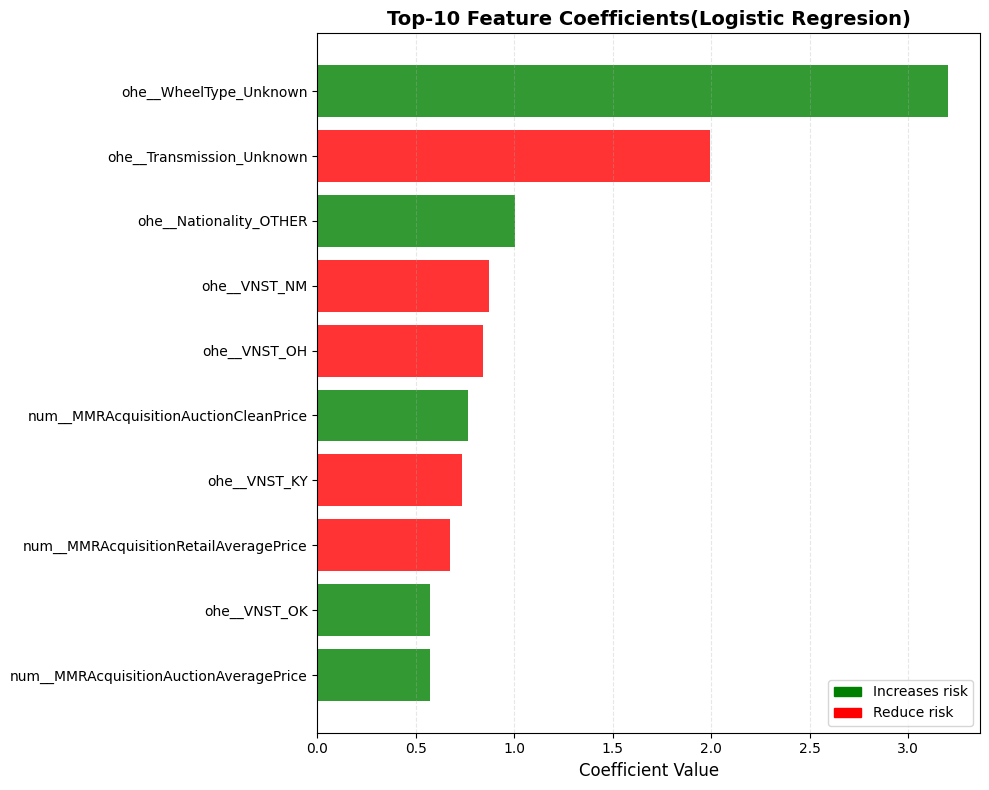

In [49]:
clf = new_features_logreg.named_steps['clf']
pp = new_features_logreg.named_steps['new_preprocessor']

weights_flat = clf.coef_[0]
feature_names = pp.get_feature_names_out()
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': weights_flat,
    'abs_coef': np.abs(weights_flat)
}).sort_values('abs_coef', ascending=False).reset_index(drop=True)

plot_df = coef_df.head(10)
colors = ['green' if x > 0 else 'red' for x in plot_df['coefficient']]
plt.figure(figsize=(10, 8))
plt.barh(plot_df['feature'], plot_df['abs_coef'], color=colors, alpha=0.8)
plt.xlabel('Coefficient Value', fontsize=12)
plt.title(f'Top-10 Feature Coefficients(Logistic Regresion)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3, linestyle='--')
from matplotlib.patches import Patch
plt.legend(
    [Patch(color='green'), Patch(color='red')],
    ['Increases risk', 'Reduce risk'],
    loc='lower right'
)
plt.tight_layout()
plt.show()


Обучим модели на 10 лучших признаках и сравним результаты:

In [67]:
top_features = coef_df.head(10)['feature'].to_list()
X_train_all = pp.transform(train_df_nf[new_numeric_features + ohe_features + te_features])
X_val_all = pp.transform(valid_df_nf[new_numeric_features + ohe_features + te_features])

top_idx = [list(feature_names).index(f) for f in top_features]

X_train_10 = X_train_all[:, top_idx]
X_val_10 = X_val_all[:, top_idx]

top_features_logreg = LogisticRegression(random_state=21)
top_features_logreg.fit(X_train_10, y_train_nf)
top_features_logreg_proba = top_features_logreg.predict_proba(X_val_10)[:, 1]

gini_top_features_logreg = gini_calculation(y_valid_nf, top_features_logreg_proba)
print(f"Gini score for top-10 features Logreg: {gini_top_features_logreg:.5f}({gini_top_features_logreg - gini_new_features_logreg:+.3f})")

Gini score for top-10 features Logreg: 0.41190(+0.036)


In [69]:
top_features_knn = KNeighborsClassifier(n_jobs=-1)
top_features_knn.fit(X_train_10, y_train_nf)
top_features_knn_proba = top_features_knn.predict_proba(X_val_10)[:, 1]

gini_top_features_knn = gini_calculation(y_valid_nf, top_features_knn_proba)
print(f"Gini score for new features KNN: {gini_top_features_knn:.5f}({gini_top_features_knn - gini_new_features_knn:+.3f})")

Gini score for new features KNN: 0.27132(+0.070)


In [70]:
top_features_gauss = GaussianNB()
top_features_gauss.fit(X_train_10, y_train_nf)
top_features_gauss_proba = top_features_gauss.predict_proba(X_val_10)[:, 1]

gini_top_features_gauss = gini_calculation(y_valid_nf, top_features_gauss_proba)
print(f"Gini score for new features GaussianNB: {gini_top_features_gauss:.5f}({gini_top_features_gauss - gini_new_features_gauss:+.3f})")

Gini score for new features GaussianNB: 0.38965(-0.030)


Как мы видим показатели значительно **увеличились** у моделей LogisticRegression и KNN

### 8.2 L1-регулризация

Теперь попробуем отсеять признаки с помощью L1 регуляризации:

In [71]:
l1_selector = SelectFromModel(
    LogisticRegression(
        penalty='l1',
        solver='saga',
        C=0.05,
        random_state=21,
        max_iter=3000,
        class_weight='balanced'
    ),
    threshold=1e-5
)

l1_logreg = Pipeline([
    ('preprocessor', new_preprocessor),
    ('selector', l1_selector),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=21, class_weight='balanced'))
])

l1_knn = Pipeline([
    ('preprocessor', new_preprocessor),
    ('selector', l1_selector),
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

l1_gauss = Pipeline([
    ('preprocessor', new_preprocessor),
    ('selector', l1_selector),
    ('scaler', StandardScaler()),
    ('clf', GaussianNB())
])

In [73]:
l1_logreg.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)
l1_logreg_proba = l1_logreg.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]

gini_l1_logreg = gini_calculation(y_valid_nf, l1_logreg_proba)
print(f"Gini score for l1 features Logreg: {gini_l1_logreg:.5f}({gini_l1_logreg - gini_new_features_logreg:+.3f})")

Gini score for l1 features Logreg: 0.48369(+0.108)


In [74]:
l1_knn.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)
l1_knn_proba = l1_knn.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]

gini_l1_knn = gini_calculation(y_valid_nf, l1_knn_proba)
print(f"Gini score for l1 features KNN: {gini_l1_knn:.5f}({gini_l1_knn - gini_new_features_knn:+.3f})")

Gini score for l1 features KNN: 0.33757(+0.136)


In [75]:
l1_gauss.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)
l1_gauss_proba = l1_gauss.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]

gini_l1_gauss = gini_calculation(y_valid_nf, l1_gauss_proba)
print(f"Gini score for l1 features GaussianNB: {gini_l1_gauss:.5f}({gini_l1_gauss - gini_new_features_gauss:+.3f})")

Gini score for l1 features GaussianNB: 0.46739(+0.048)


Выведем признаки, которые были сохранены после регуляризации L1

In [98]:
selector = l1_logreg.named_steps['selector']
preprocessor = l1_logreg.named_steps['preprocessor']
selected_mask = selector.get_support()
all_feature_names = preprocessor.get_feature_names_out()
selected_features = all_feature_names[selected_mask]

print(f"Отобрано признаков: {selected_mask.sum()} из {len(all_feature_names)}")
print("\nСписок отобранных признаков:")
for name in selected_features:
    print(f"{name}")

Отобрано признаков: 34 из 70

Список отобранных признаков:
num__VehYear
num__VehicleAge
num__VehOdo
num__MMRAcquisitionAuctionAveragePrice
num__MMRCurrentRetailCleanPrice
num__VehBCost
num__year_millage
num__sin_month
ohe__Auction_MANHEIM
ohe__Auction_OTHER
ohe__Transmission_MANUAL
ohe__WheelType_Covers
ohe__WheelType_Unknown
ohe__Nationality_OTHER ASIAN
ohe__Size_LARGE
ohe__Size_LARGE TRUCK
ohe__Size_MEDIUM
ohe__Size_MEDIUM SUV
ohe__Size_SMALL TRUCK
ohe__Size_SPECIALTY
ohe__Size_VAN
ohe__VNST_CO
ohe__VNST_FL
ohe__VNST_GA
ohe__VNST_NC
ohe__VNST_NM
ohe__VNST_OK
ohe__VNST_SC
ohe__VNST_TX
ohe__VNST_VA
te__Make
te__Model
te__Trim
te__SubModel


Отбор признаков с помощью L1-регуляризации показал результаты еще лучше

## 9. Подбор гиперпараметров для лучшей модели.

Проанализируем результаты и выберем лучшую модель:

In [40]:
score = pd.DataFrame({
    'model': ['LR', 'KNN', 'GNB', 'myLR', 'myKNN', 'myGNB', 'newFeaturesLR', 'newFeaturesKNN', 'newFeaturesGNB', 'top10featuresLR', 'top10featuresKNN', 'top10featuresGNB', 'l1LR', 'l1KNN', 'l1GNB'],
    'gini': [gini_log, gini_knn, gini_gauss, gini_my_logreg, gini_my_knn, gini_my_gauss, gini_new_features_logreg, gini_new_features_knn, gini_new_features_gauss, gini_top_features_logreg, gini_top_features_knn, gini_top_features_gauss, gini_l1_logreg, gini_l1_knn, gini_l1_gauss]
})
score = score.sort_values('gini', ascending=False).reset_index(drop=True)
score

,model,gini
0,l1LR,0.483686
1,l1GNB,0.467393
2,newFeaturesGNB,0.419291
3,myGNB,0.412674
4,GNB,0.412602
5,top10featuresLR,0.411897
6,top10featuresGNB,0.389646
7,LR,0.384413
8,newFeaturesLR,0.375945
9,l1KNN,0.337570


Лучше всех показала себя модель LogisticRegression с отфильтрованными L1-регулязацией признаками

Подберем оптимальные параметры для лучшей модели с помощью Optuna:

In [76]:
def objective(trial):
  sel_C = trial.suggest_float('selector__estimator__C', 0.005, 0.5, log=True)
  clf_C = trial.suggest_float('clf__C', 1e-3, 5.0, log=True)

  pipe = clone(l1_logreg)
  pipe.set_params(
      selector__estimator__C=sel_C,
      clf__C=clf_C,
      clf__max_iter=2000,
      clf__solver='lbfgs',
      clf__penalty='l2'
  )
  try:
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=21)
    scores = cross_val_score(pipe, train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf, cv=cv, scoring='roc_auc', n_jobs=1)
    return 2 * scores.mean() - 1
  except Exception:
    return -1.0

study = optuna.create_study(direction="maximize", pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
study.optimize(objective, n_trials=10, show_progress_bar=True)

print(f"Лучший gini: {study.best_value}")
print(f"Параметры: {study.best_params}")

[I 2026-04-09 20:16:52,886] A new study created in memory with name: no-name-aad46e90-a0ce-4be9-81be-ebb8dd69485c


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-04-09 20:17:16,434] Trial 0 finished with value: 0.49776151917625433 and parameters: {'selector__estimator__C': 0.015686739693084265, 'clf__C': 0.34520518439132036}. Best is trial 0 with value: 0.49776151917625433.
[I 2026-04-09 20:17:38,028] Trial 1 finished with value: 0.4985264894494732 and parameters: {'selector__estimator__C': 0.009817480213690152, 'clf__C': 0.0018201437939014034}. Best is trial 1 with value: 0.4985264894494732.
[I 2026-04-09 20:17:55,486] Trial 2 finished with value: 0.49666291176177135 and parameters: {'selector__estimator__C': 0.005823324564594051, 'clf__C': 0.7204232553887285}. Best is trial 1 with value: 0.4985264894494732.
[I 2026-04-09 20:18:22,035] Trial 3 finished with value: 0.4955151832621645 and parameters: {'selector__estimator__C': 0.05143805953075934, 'clf__C': 0.24583315040029743}. Best is trial 1 with value: 0.4985264894494732.
[I 2026-04-09 20:19:19,846] Trial 4 finished with value: 0.4950220621194461 and parameters: {'selector__estimator

Обучим модель на лучших параметрах:

In [77]:
best_pipe = clone(l1_logreg)
best_pipe.set_params(**study.best_params)
best_pipe.fit(train_df_nf[new_numeric_features + ohe_features + te_features], y_train_nf)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler_1',
                                                                   StandardScaler())]),
                                                  ['VehYear', 'VehicleAge',
                                                   'VehOdo',
                                                   'MMRAcquisitionAuctionAveragePrice',
                                                   'MMRAcquisitionAuctionCleanPrice',
                                                   'MMRAcquisitionRetailAveragePrice',
                                                   'MMRAcquisitonRetailCleanPrice',
                                                   'MMRCurrentAucti...
                                                  ['Make', 'Model', 'Trim',
                                                   'SubModel'])])),
                ('selector',
                 SelectFromModel(estimator=LogisticRegression(C=0.026921534518788925,
                                                              class_weight='balanced',
                                                              max_iter=3000,
                                                              penalty='l1',
                                                              random_state=21,
                                                              solver='saga'),
                                 threshold=1e-05)),
                ('scaler', StandardScaler()),
                ('clf',
                 LogisticRegression(C=0.15707081028814968,
                                    class_weight='balanced', max_iter=1000,
                                    random_state=21))])

## 10. Результаты

Оценим лучшую модель:

In [80]:
best_pipe_proba_tr = best_pipe.predict_proba(train_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]
gini_best_model_tr = gini_calculation(y_train_nf, best_pipe_proba_tr)

best_pipe_proba_val = best_pipe.predict_proba(valid_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]
gini_best_model_val = gini_calculation(y_valid_nf, best_pipe_proba_val)

best_pipe_proba_test = best_pipe.predict_proba(test_df_nf[new_numeric_features + ohe_features + te_features])[:, 1]
gini_best_model_test = gini_calculation(y_test_nf, best_pipe_proba_test)


In [81]:
best_score = pd.DataFrame({
    'set': ['train', 'valid', 'test'],
    'Gini': [gini_best_model_tr, gini_best_model_val, gini_best_model_test],
    })
best_score

,set,Gini
0,train,0.534893
1,valid,0.480432
2,test,0.505306


Как мы видим модель стабильно работает на всех данных, что означает, что она обучена в меру и хорошо улавливает зависимости

## 11. Метрики

Реализуем методы подсчета метрик:

In [82]:
def confusion_matrix(y_true, y_pred):
  y_true = np.asarray(y_true).flatten()
  y_pred = np.asarray(y_pred).flatten()

  TP = np.sum((y_true == 1) & (y_pred == 1))
  TN = np.sum((y_true == 0) & (y_pred == 0))
  FP = np.sum((y_true == 0) & (y_pred == 1))
  FN = np.sum((y_true == 1) & (y_pred == 0))

  return TP, TN, FP, FN

In [83]:
def recall_score(y_true, y_pred, eps=1e-10):
  TP, TN, FP, FN = confusion_matrix(y_true, y_pred)
  return TP / (TP + FN + eps)


In [84]:
def precision_score(y_true, y_pred, eps=1e-10):
  TP, TN, FP, FN = confusion_matrix(y_true, y_pred)
  return TP / (TP + FP + eps)

In [85]:
def f1_score(y_true, y_pred, eps=1e-10):
  p = precision_score(y_true, y_pred)
  r = recall_score(y_true, y_pred)
  return 2 * p * r / (p + r + eps)

In [86]:
def pr_curve_man(y_true, y_proba, n_thresholds=100):
  y_true = np.asarray(y_true).flatten()
  y_pred = np.asarray(y_proba).flatten()

  thresholds = np.linspace(1.0, 0.0, n_thresholds)
  precisions, recalls = [], []

  for t in thresholds:
    y_pred = (y_proba >= t).astype(int)
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    precisions.append(p)
    recalls.append(r)

  return np.array(precisions), np.array(recalls), thresholds

def auc_trapezoidal(x, y):
  idx = np.argsort(x)
  x_sorted = x[idx]
  y_sorted = y[idx]

  dx = np.diff(x_sorted)
  dy_avg = (y_sorted[1:] + y_sorted[:-1]) / 2
  return np.sum(dx * dy_avg)

def auc_pr_score(y_true, y_proba, n_thresholds=200):
  precisions, recalls, _ = pr_curve_man(y_true, y_proba, n_thresholds)
  return auc_trapezoidal(recalls, precisions)

Построим график Precision-Recall и вычислим метрики:

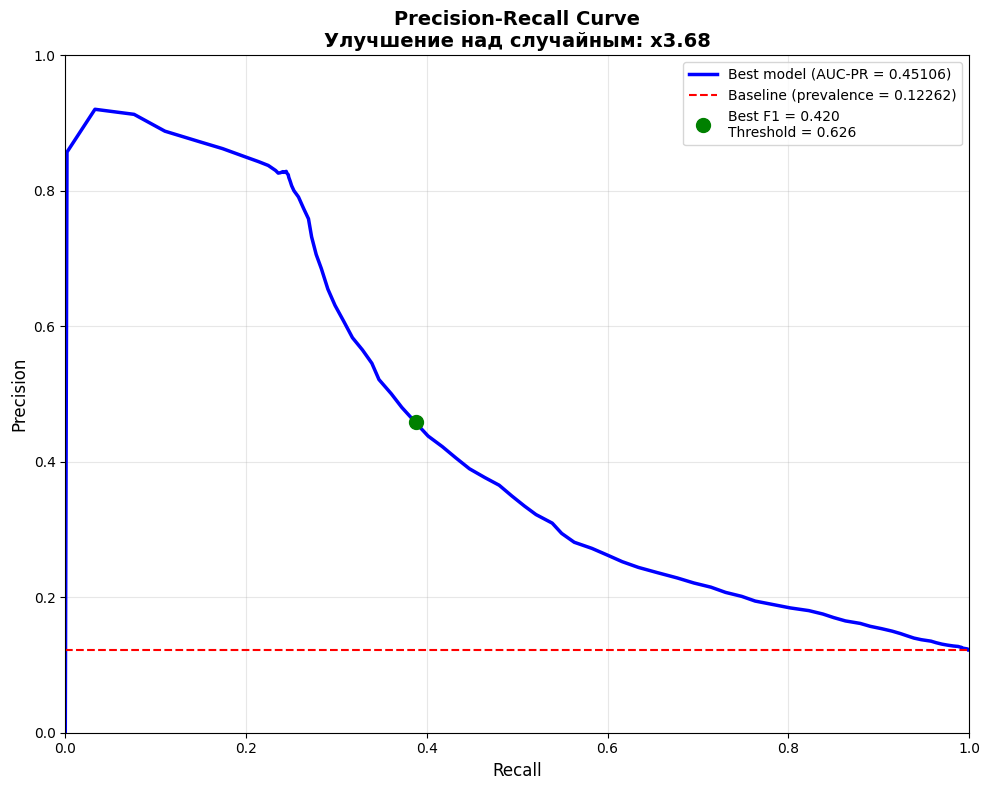

In [95]:
precision, recall, thresholds = pr_curve_man(y_test_nf, best_pipe_proba_test)
auc_pr = auc_pr_score(y_test_nf, best_pipe_proba_test)
baseline = y_test_nf.mean()

plt.figure(figsize=(10, 8))
plt.plot(recall, precision, 'b-', linewidth=2.5, label=f'Best model (AUC-PR = {auc_pr:.5f})')
plt.axhline(y=baseline, color='r', linestyle='--', linewidth=1.5, label=f'Baseline (prevalence = {baseline:.5f})')

f1_scores = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
plt.plot(recall[best_idx], precision[best_idx], 'go', markersize=10,
         label=f'Best F1 = {f1_scores[best_idx]:.3f}\nThreshold = {thresholds[best_idx]:.3f}')

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title(f'Precision-Recall Curve\nУлучшение над случайным: x{auc_pr / baseline:.2f}',
          fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=10)
plt.grid(alpha=0.3)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.tight_layout()
plt.show()

In [96]:
threshold = 0.626

y_pred = (best_pipe_proba_test >= threshold).astype(int)
print(f"Recall: {recall_score(y_test_nf, y_pred)}")
print(f"Precision: {precision_score(y_test_nf, y_pred)}")
print(f"F1: {f1_score(y_test_nf, y_pred)}")
print(f"AUC-PR: {auc_pr_score(y_test_nf, best_pipe_proba_test)}")

Recall: 0.3878711307643592
Precision: 0.4575260804768831
F1: 0.41982905977938495
AUC-PR: 0.4510634695232234


Выбрав порог - 0.626 для максимального F1, мы получаем оптимальные показатели метрик, которые означают что:


*   39% из всех бракованых машин были **найдены** моделью
*   46% машин из тех, которые мадель забраковала были **действительно бракованы**



Меняя порог классов(threshold) мы можем добиться необходимых нам показателей работы моделей, в зависимости от того что нам важнее: убрать как можно больше "плохих" машин с рынка вне зависимости от того сколько "хороших" машин модель забракует, либо же наоборот

## 12. Заключение

В процессе работы над данным проектом, мы обучили модель, на основании имеющихся признаков, распознавать бракованные авто с результатом целевой метрики AUC-PR = 0.45

Для данной задачи лучше всего использовать hard-label метрику Recall, так как она показывает, какой процент из всех имеющихся бракованных авто модель распознает, т.к. затраты на проверку авто значительно ниже, чем ущерб от продажи некачественного экземпляра.